# Practical 2: Email Spam Classification

**Aim:** Classify emails as **0 = Not Spam** or **1 = Spam** using K-Nearest Neighbors (KNN) and Support Vector Machine (SVM).

**Dataset:** Download `emails.csv` from the Kaggle Email Spam Classification dataset and keep it in the same folder as this notebook.

Run the cells from top to bottom using **Shift + Enter**.

## Cell 1: Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

## Cell 2: Load Dataset

In [2]:
df = pd.read_csv("emails.csv")

print(df.head())
print(df.shape)
print(df.isnull().sum().sum())

  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]
(5172, 3002)
0


## Cell 3: Preprocess Dataset

- Remove rows with missing values.
- Remove the email ID column because it is not useful for prediction.
- Use `Prediction` as the target column.
- The remaining word-count columns are the input features.

In [3]:
df = df.dropna()
X = df.drop(columns=["Email No.", "Prediction"])
y = df["Prediction"]

print("Features:", X.shape)
print(y.value_counts())

Features: (5172, 3000)
Prediction
0    3672
1    1500
Name: count, dtype: int64


## Cell 4: Split and Normalize Data

Use 80% of the data for training and 20% for testing. Normalization scales the word counts so that large counts do not dominate distance-based models such as KNN.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train = normalize(X_train)
X_test = normalize(X_test)

## Cell 5: Train K-Nearest Neighbors (KNN)

In [9]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

pred_knn = knn.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, pred_knn))
print("KNN Precision:", precision_score(y_test, pred_knn, zero_division=0))
print("KNN Recall:", recall_score(y_test, pred_knn, zero_division=0))
print("KNN F1 Score:", f1_score(y_test, pred_knn, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, pred_knn))

KNN Accuracy: 0.8714975845410629
KNN Precision: 0.7667731629392971
KNN Recall: 0.8
KNN F1 Score: 0.7830342577487766
Confusion Matrix:
 [[662  73]
 [ 60 240]]


## Cell 6: Train Support Vector Machine (SVM)

In [10]:
svm = SVC(kernel="linear")
svm.fit(X_train, y_train)

pred_svm = svm.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, pred_svm))
print("SVM Precision:", precision_score(y_test, pred_svm, zero_division=0))
print("SVM Recall:", recall_score(y_test, pred_svm, zero_division=0))
print("SVM F1 Score:", f1_score(y_test, pred_svm, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, pred_svm))

SVM Accuracy: 0.9188405797101449
SVM Precision: 0.8802816901408451
SVM Recall: 0.8333333333333334
SVM F1 Score: 0.8561643835616438
Confusion Matrix:
 [[701  34]
 [ 50 250]]


## Cell 7: Confusion Matrices

A confusion matrix shows correct and incorrect predictions for spam and not-spam emails.

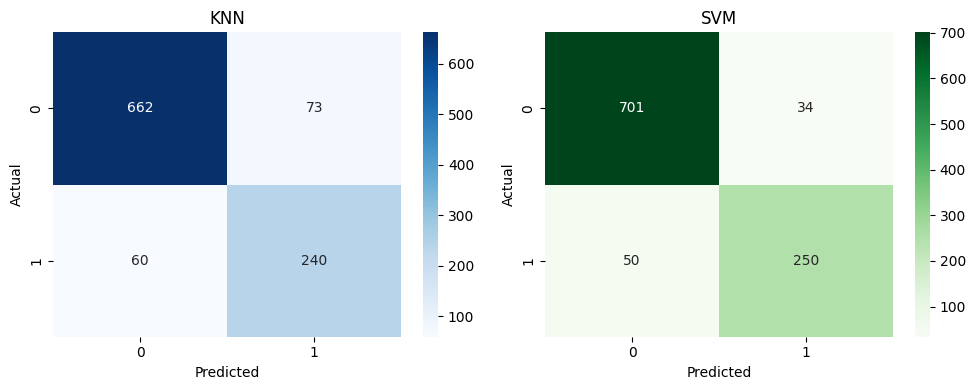

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(confusion_matrix(y_test, pred_knn), annot=True, fmt="d",
            cmap="Blues", ax=axes[0])
axes[0].set_title("KNN")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(confusion_matrix(y_test, pred_svm), annot=True, fmt="d",
            cmap="Greens", ax=axes[1])
axes[1].set_title("SVM")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

## Cell 8: Compare Both Models

In [8]:
results = pd.DataFrame({
    "Model": ["KNN", "SVM"],
    "Accuracy": [accuracy_score(y_test, pred_knn), accuracy_score(y_test, pred_svm)],
    "Precision": [precision_score(y_test, pred_knn, zero_division=0),
                  precision_score(y_test, pred_svm, zero_division=0)],
    "Recall": [recall_score(y_test, pred_knn, zero_division=0),
               recall_score(y_test, pred_svm, zero_division=0)],
    "F1 Score": [f1_score(y_test, pred_knn, zero_division=0),
                 f1_score(y_test, pred_svm, zero_division=0)]
})

print(results.round(3))

  Model  Accuracy  Precision  Recall  F1 Score
0   KNN     0.871      0.767   0.800     0.783
1   SVM     0.919      0.880   0.833     0.856


## Result

Email spam classification was performed using K-Nearest Neighbors (KNN) and Support Vector Machine (SVM). Both models were evaluated using Accuracy, Precision, Recall and F1 Score. Compare the values printed above to determine which model performed better on the test dataset.

## Quick Viva Questions

1. **What is classification?** Predicting a category or class label.
2. **What is spam?** An unwanted or unsolicited email.
3. **What is KNN?** A classification algorithm that predicts a class using the nearest training examples.
4. **What is SVM?** A model that finds a decision boundary separating classes.
5. **Why split the dataset?** To train on one part and test performance on unseen data.
6. **What is accuracy?** The fraction of predictions that are correct.
7. **What is precision?** Of emails predicted as spam, how many were actually spam?
8. **What is recall?** Of actual spam emails, how many were detected?
9. **What is F1 score?** A combined measure of precision and recall.